# ResNet50 K-Fold Training from Manifests

This notebook trains a competition-safe ResNet50 baseline using the manifests generated by `01_setup_data.ipynb`.

Main improvements over the earlier notebook:
- loads data from saved manifests
- uses `image_path` directly from the manifest
- supports Etsy-only or Etsy+external experiments
- optional class weighting for imbalanced datasets
- stores fold checkpoints, OOF predictions, threshold tuning results, and submissions in experiment-specific folders

In [29]:
import copy
import json
import math
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.api.types import is_numeric_dtype
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import models, transforms

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score, 
    recall_score,
    f1_score,
)
from sklearn.model_selection import StratifiedKFold

from tqdm.auto import tqdm

print("torch:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("device name:", torch.cuda.get_device_name(0))

torch: 2.12.0.dev20260319+cu128
cuda available: True
device name: NVIDIA GeForce RTX 5060 Laptop GPU


## 1. Configuration

In [30]:
CONFIG = {
    # --- project / files ---
    "project_root_override": None,
    "root_markers": ["data2", "outputs"],

    # Choose the training manifest to use.
    # Recommended order for experiments:
    # 1) train_manifest_etsy_only.csv
    # 2) train_manifest_etsy_plus_external.csv 
    # 3) later: a balanced external version if you create one 
    "train_manifest_relpath": "outputs/manifests/train_manifest_etsy_plus_external.csv",
    "test_manifest_relpath": "outputs/manifests/test_manifest_etsy.csv",

    # Experiment name controls output folders/files
    "experiment_name": "resnet50_etsy_ai5_3_v1",

    # --- labels ---
    "positive_label": "ai_generated",
    "negative_label": "authentic",

    # --- hardware / loader ---
    "device": "cuda" if torch.cuda.is_available() else "cpu",
    "num_workers": 4,
    "batch_size": 32,

    # --- image / transforms ---
    "img_size": 224,
    "train_horizontal_flip": True,
    "train_rotation_degrees": 10,
    "train_color_jitter": True,

    # --- CV / training ---
    "random_state": 42,
    "n_splits": 5,
    "epochs_head": 3,
    "epochs_fine": 5,
    "lr_head": 1e-3,
    "lr_layer4": 1e-4,
    "lr_fc_fine": 5e-4,
    "patience": 2,

    # --- imbalance handling ---
    # Useful when external data creates skew.
    "use_class_weights": True,
    "use_weighted_sampler": False,

    # --- misc ---
    "save_oof_csv": True,
    "save_test_probs_csv": True,
    "save_submission_csv": True,
}

In [31]:
def find_project_root(start: Path, markers: list[str]) -> Path:
    start = start.resolve()
    for candidate in [start] + list(start.parents):
        if all((candidate / m).exists() for m in markers):
            return candidate
    raise FileNotFoundError(
        f"Could not find project root from {start}. Tried markers: {markers}"
    )

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(CONFIG["random_state"])

cwd = Path.cwd()
if CONFIG["project_root_override"]:
    PROJECT_ROOT = Path(CONFIG["project_root_override"]).expanduser().resolve()
else:
    PROJECT_ROOT = find_project_root(cwd, CONFIG["root_markers"])

DEVICE = torch.device(CONFIG["device"])

TRAIN_MANIFEST_PATH = PROJECT_ROOT / CONFIG["train_manifest_relpath"]
TEST_MANIFEST_PATH = PROJECT_ROOT / CONFIG["test_manifest_relpath"]

EXPERIMENT_DIR = PROJECT_ROOT / "outputs" / "experiments" / CONFIG["experiment_name"]
MODELS_DIR = EXPERIMENT_DIR / "models"
REPORTS_DIR = EXPERIMENT_DIR / "reports"
SUBMISSIONS_DIR = EXPERIMENT_DIR / "submissions"

for d in [EXPERIMENT_DIR, MODELS_DIR, REPORTS_DIR, SUBMISSIONS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT       :", PROJECT_ROOT)
print("TRAIN_MANIFEST_PATH:", TRAIN_MANIFEST_PATH)
print("TEST_MANIFEST_PATH :", TEST_MANIFEST_PATH)
print("EXPERIMENT_DIR     :", EXPERIMENT_DIR)
print("DEVICE             :", DEVICE)

PROJECT_ROOT       : /home/tbeliere/Projects/DCU/AML_PJ
TRAIN_MANIFEST_PATH: /home/tbeliere/Projects/DCU/AML_PJ/outputs/manifests/train_manifest_etsy_plus_external.csv
TEST_MANIFEST_PATH : /home/tbeliere/Projects/DCU/AML_PJ/outputs/manifests/test_manifest_etsy.csv
EXPERIMENT_DIR     : /home/tbeliere/Projects/DCU/AML_PJ/outputs/experiments/resnet50_etsy_ai5_3_v1
DEVICE             : cuda


## 2. Load manifests

In [32]:
train_df = pd.read_csv(TRAIN_MANIFEST_PATH)
test_df = pd.read_csv(TEST_MANIFEST_PATH)

print("train_df shape:", train_df.shape)
print("test_df shape :", test_df.shape)
display(train_df.head())
display(test_df.head())

print(train_df['label'].dtype)

train_df shape: (5795, 12)
test_df shape : (2058, 12)


,image_id,image_path,label,source,split,file_exists,valid_image,width,height,mode,format,aspect_ratio
0,ai5_3/Ai_generated_dataset/animals/image-10.png,/home/tbeliere/Projects/DCU/AML_PJ/data2/other...,ai_generated,ai5_3,train,True,True,512,512,RGB,PNG,1.0
1,ai5_3/Ai_generated_dataset/animals/image-11.png,/home/tbeliere/Projects/DCU/AML_PJ/data2/other...,ai_generated,ai5_3,train,True,True,512,512,RGB,PNG,1.0
2,ai5_3/Ai_generated_dataset/animals/image-12.png,/home/tbeliere/Projects/DCU/AML_PJ/data2/other...,ai_generated,ai5_3,train,True,True,512,512,RGB,PNG,1.0
3,ai5_3/Ai_generated_dataset/animals/image-13.png,/home/tbeliere/Projects/DCU/AML_PJ/data2/other...,ai_generated,ai5_3,train,True,True,512,512,RGB,PNG,1.0
4,ai5_3/Ai_generated_dataset/animals/image-14.png,/home/tbeliere/Projects/DCU/AML_PJ/data2/other...,ai_generated,ai5_3,train,True,True,512,512,RGB,PNG,1.0


,image_id,image_path,label,source,split,file_exists,valid_image,width,height,mode,format,aspect_ratio
0,000317ef-6928-48ca-9b51-7742ab8dfb86.jpg,/home/tbeliere/Projects/DCU/AML_PJ/data2/etsy_...,NaN,etsy,test,True,True,1024,1024,RGB,JPEG,1.000000
1,000a811d-cf8f-4b5b-be75-bd9f1a73c098.jpg,/home/tbeliere/Projects/DCU/AML_PJ/data2/etsy_...,NaN,etsy,test,True,True,1024,1024,RGB,JPEG,1.000000
2,003a1394-83c5-41c0-9cd5-18ac89397c7b.jpg,/home/tbeliere/Projects/DCU/AML_PJ/data2/etsy_...,NaN,etsy,test,True,True,1195,896,RGB,JPEG,1.333705
3,00888016-16c4-4ce7-a03e-073f04a1a9c8.jpg,/home/tbeliere/Projects/DCU/AML_PJ/data2/etsy_...,NaN,etsy,test,True,True,1024,1024,RGB,JPEG,1.000000
4,00e301e1-7520-4abb-8007-9e00a0b04da6.jpg,/home/tbeliere/Projects/DCU/AML_PJ/data2/etsy_...,NaN,etsy,test,True,True,896,1195,RGB,JPEG,0.749791


str


In [33]:
required_train_cols = {"image_id", "image_path", "label"}
required_test_cols = {"image_id", "image_path"}

missing_train_cols = required_train_cols - set(train_df.columns)
missing_test_cols = required_test_cols - set(test_df.columns)

if missing_train_cols:
    raise ValueError(f"Train manifest missing columns: {missing_train_cols}")
if missing_test_cols:
    raise ValueError(f"Test manifest missing columns: {missing_test_cols}")

# Keep only healthy rows if these flags exist
if "file_exists" in train_df.columns:
    train_df = train_df[train_df["file_exists"]].copy()
if "valid_image" in train_df.columns:
    train_df = train_df[train_df["valid_image"]].copy()

if "file_exists" in test_df.columns:
    test_df = test_df[test_df["file_exists"]].copy()
if "valid_image" in test_df.columns:
    test_df = test_df[test_df["valid_image"]].copy()

label2id = {
    CONFIG["negative_label"]: 0,
    CONFIG["positive_label"]: 1,
}
id2label = {v: k for k, v in label2id.items()}

# support either string labels or already-numeric labels
if is_numeric_dtype(train_df["label"]):
    train_df["target"] = train_df["label"].astype(int)
else:
    train_df["target"] = train_df["label"].astype(str).str.strip().map(label2id)

    if train_df["target"].isna().any():
        bad_labels = sorted(train_df.loc[train_df["target"].isna(), "label"].astype(str).unique())
        raise ValueError(f"Unmapped labels found in train_df['label']: {bad_labels}")

train_df["target"] = train_df["target"].astype(int)

print("Filtered train rows:", len(train_df))
print("Filtered test rows :", len(test_df))
print("\nTrain label distribution:")
print(train_df["target"].value_counts().sort_index())
if "source" in train_df.columns:
    print("\nTrain source distribution:")
    print(train_df["source"].value_counts())

Filtered train rows: 5795
Filtered test rows : 2058

Train label distribution:
target
0    3230
1    2565
Name: count, dtype: int64

Train source distribution:
source
etsy     4800
ai5_3     995
Name: count, dtype: int64


## 3. Transforms and dataset

In [34]:
train_transform = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.RandomHorizontalFlip() if CONFIG["train_horizontal_flip"] else transforms.Lambda(lambda x: x),
    transforms.RandomRotation(CONFIG["train_rotation_degrees"]) if CONFIG["train_rotation_degrees"] else transforms.Lambda(lambda x: x),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.02) if CONFIG["train_color_jitter"] else transforms.Lambda(lambda x: x),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

In [35]:
class ManifestImageDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform=None, is_test: bool = False):
        self.df = df.reset_index(drop=True).copy()
        self.transform = transform
        self.is_test = is_test

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = Path(row["image_path"])
        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        if self.is_test:
            return image, row["image_id"]

        label = int(row["target"])
        return image, label

## 4. Model and training utilities

In [36]:
def build_model():
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    model.fc = nn.Linear(model.fc.in_features, 2)
    return model.to(DEVICE)

def set_phase1_trainable(model):
    for param in model.parameters():
        param.requires_grad = False
    for param in model.fc.parameters():
        param.requires_grad = True

def set_phase2_trainable(model):
    for param in model.parameters():
        param.requires_grad = False
    for param in model.layer4.parameters():
        param.requires_grad = True
    for param in model.fc.parameters():
        param.requires_grad = True

def make_phase1_optimizer(model):
    return torch.optim.Adam(model.fc.parameters(), lr=CONFIG["lr_head"])

def make_phase2_optimizer(model):
    return torch.optim.Adam([
        {"params": model.layer4.parameters(), "lr": CONFIG["lr_layer4"]},
        {"params": model.fc.parameters(), "lr": CONFIG["lr_fc_fine"]},
    ])

def make_scheduler(optimizer):
    return torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=1,
    )

def make_criterion(train_targets: np.ndarray):
    if CONFIG["use_class_weights"]:
        class_counts = np.bincount(train_targets, minlength=2)
        weights = len(train_targets) / (2.0 * class_counts)
        weight_tensor = torch.tensor(weights, dtype=torch.float32, device=DEVICE)
        print("Using class weights:", weights)
        return nn.CrossEntropyLoss(weight=weight_tensor)
    return nn.CrossEntropyLoss()

def make_train_loader(train_split: pd.DataFrame):
    dataset = ManifestImageDataset(train_split, transform=train_transform, is_test=False)

    if CONFIG["use_weighted_sampler"]:
        targets = train_split["target"].values
        class_counts = np.bincount(targets, minlength=2)
        class_weights = 1.0 / class_counts
        sample_weights = class_weights[targets]
        sampler = WeightedRandomSampler(
            weights=torch.DoubleTensor(sample_weights),
            num_samples=len(sample_weights),
            replacement=True,
        )
        return DataLoader(
            dataset,
            batch_size=CONFIG["batch_size"],
            sampler=sampler,
            num_workers=CONFIG["num_workers"],
            pin_memory=torch.cuda.is_available(),
        )

    return DataLoader(
        dataset,
        batch_size=CONFIG["batch_size"],
        shuffle=True,
        num_workers=CONFIG["num_workers"],
        pin_memory=torch.cuda.is_available(),
    )

def make_val_loader(val_split: pd.DataFrame):
    dataset = ManifestImageDataset(val_split, transform=val_transform, is_test=False)
    return DataLoader(
        dataset,
        batch_size=CONFIG["batch_size"],
        shuffle=False,
        num_workers=CONFIG["num_workers"],
        pin_memory=torch.cuda.is_available(),
    )

In [37]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in tqdm(loader, desc="Training", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds)
    return epoch_loss, epoch_f1

def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validating", leave=False):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds)
    return epoch_loss, epoch_f1, np.array(all_labels), np.array(all_preds)

def predict_val_proba(model, loader, device):
    model.eval()
    all_probs = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Val probabilities", leave=False):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)[:, 1]

            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return np.array(all_probs), np.array(all_labels)

## 5. One-fold training helper

In [38]:
def run_one_fold(fold, train_idx, val_idx, train_df):
    print(f"\n========== FOLD {fold + 1}/{CONFIG['n_splits']} ==========")

    train_split = train_df.iloc[train_idx].reset_index(drop=True)
    val_split = train_df.iloc[val_idx].reset_index(drop=True)

    print("Train size:", len(train_split))
    print("Val size  :", len(val_split))
    print("Train label counts:")
    print(train_split["target"].value_counts().sort_index())

    train_loader = make_train_loader(train_split)
    val_loader = make_val_loader(val_split)

    model = build_model()
    criterion = make_criterion(train_split["target"].values)

    history = []
    best_f1 = -1.0
    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_labels = None
    best_val_preds = None
    best_val_probs = None

    # Phase 1
    print("\n--- Phase 1: train fc only ---")
    set_phase1_trainable(model)
    optimizer = make_phase1_optimizer(model)

    for epoch in range(CONFIG["epochs_head"]):
        print(f"Phase 1 - Epoch {epoch + 1}/{CONFIG['epochs_head']}")
        train_loss, train_f1 = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
        val_loss, val_f1, val_labels, val_preds = validate_one_epoch(model, val_loader, criterion, DEVICE)

        history.append({
            "fold": fold + 1,
            "phase": 1,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_f1": train_f1,
            "val_loss": val_loss,
            "val_f1": val_f1,
        })

        print(f"Train loss: {train_loss:.4f} | Train F1: {train_f1:.4f}")
        print(f"Val   loss: {val_loss:.4f} | Val   F1: {val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_model_wts = copy.deepcopy(model.state_dict())
            best_val_labels = val_labels
            best_val_preds = val_preds

    # Phase 2
    print("\n--- Phase 2: unfreeze layer4 + fc ---")
    set_phase2_trainable(model)
    optimizer = make_phase2_optimizer(model)
    scheduler = make_scheduler(optimizer)

    epochs_without_improvement = 0

    for epoch in range(CONFIG["epochs_fine"]):
        print(f"Phase 2 - Epoch {epoch + 1}/{CONFIG['epochs_fine']}")
        train_loss, train_f1 = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
        val_loss, val_f1, val_labels, val_preds = validate_one_epoch(model, val_loader, criterion, DEVICE)

        history.append({
            "fold": fold + 1,
            "phase": 2,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_f1": train_f1,
            "val_loss": val_loss,
            "val_f1": val_f1,
        })

        scheduler.step(val_f1)

        print(f"Train loss: {train_loss:.4f} | Train F1: {train_f1:.4f}")
        print(f"Val   loss: {val_loss:.4f} | Val   F1: {val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_model_wts = copy.deepcopy(model.state_dict())
            best_val_labels = val_labels
            best_val_preds = val_preds
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= CONFIG["patience"]:
                print(f"Early stopping in fold {fold + 1}")
                break

    model.load_state_dict(best_model_wts)
    best_val_probs, best_val_true = predict_val_proba(model, val_loader, DEVICE)

    fold_model_path = MODELS_DIR / f"best_resnet50_fold{fold + 1}.pt"
    torch.save(model.state_dict(), fold_model_path)
    print("Saved:", fold_model_path)

    return {
        "model": model,
        "history": history,
        "best_f1": best_f1,
        "val_labels": best_val_labels,
        "val_preds": best_val_preds,
        "val_probs": best_val_probs,
        "val_true": best_val_true,
        "fold_model_path": fold_model_path,
    }

## 6. K-Fold training

In [39]:
skf = StratifiedKFold(
    n_splits=CONFIG["n_splits"],
    shuffle=True,
    random_state=CONFIG["random_state"],
)

X = train_df["image_id"].values
y = train_df["target"].values

fold_results = []
all_histories = []

best_fold_model = None
best_fold_f1 = -1.0
best_fold_id = None
best_fold_labels = None
best_fold_preds = None

oof_probs = np.zeros(len(train_df), dtype=float)
oof_true = train_df["target"].values.copy()

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    result = run_one_fold(
        fold=fold,
        train_idx=train_idx,
        val_idx=val_idx,
        train_df=train_df,
    )

    fold_results.append(result["best_f1"])
    all_histories.extend(result["history"])
    oof_probs[val_idx] = result["val_probs"]

    print(f"Best F1 for fold {fold + 1}: {result['best_f1']:.4f}")

    if result["best_f1"] > best_fold_f1:
        best_fold_f1 = result["best_f1"]
        best_fold_model = result["model"]
        best_fold_id = fold + 1
        best_fold_labels = result["val_labels"]
        best_fold_preds = result["val_preds"]

print("\n========== K-FOLD RESULTS ==========")
print("F1 scores:", [round(x, 4) for x in fold_results])
print("Mean F1  :", round(float(np.mean(fold_results)), 4))
print("Std F1   :", round(float(np.std(fold_results)), 4))
print("Best fold:", best_fold_id, "| Best F1:", round(float(best_fold_f1), 4))


========== FOLD 1/5 ==========
Train size: 4636
Val size  : 1159
Train label counts:
target
0    2584
1    2052
Name: count, dtype: int64
Using class weights: [0.89705882 1.12962963]

--- Phase 1: train fc only ---
Phase 1 - Epoch 1/3


Train loss: 0.5746 | Train F1: 0.6821
Val   loss: 0.5208 | Val   F1: 0.7508
Phase 1 - Epoch 2/3


Train loss: 0.4738 | Train F1: 0.7707
Val   loss: 0.5215 | Val   F1: 0.7557
Phase 1 - Epoch 3/3


Train loss: 0.4429 | Train F1: 0.7865
Val   loss: 0.4854 | Val   F1: 0.7715

--- Phase 2: unfreeze layer4 + fc ---
Phase 2 - Epoch 1/5


Train loss: 0.3866 | Train F1: 0.8083
Val   loss: 0.3742 | Val   F1: 0.8258
Phase 2 - Epoch 2/5


Train loss: 0.2011 | Train F1: 0.9102
Val   loss: 0.3771 | Val   F1: 0.8298
Phase 2 - Epoch 3/5


... (35 outputs left out)

Train loss: 0.1191 | Train F1: 0.9530
Val   loss: 0.5168 | Val   F1: 0.8112
Phase 2 - Epoch 4/5


Train loss: 0.0661 | Train F1: 0.9755
Val   loss: 0.4358 | Val   F1: 0.8292
Phase 2 - Epoch 5/5


Train loss: 0.0405 | Train F1: 0.9859
Val   loss: 0.4846 | Val   F1: 0.8401


Saved: /home/tbeliere/Projects/DCU/AML_PJ/outputs/experiments/resnet50_etsy_ai5_3_v1/models/best_resnet50_fold5.pt
Best F1 for fold 5: 0.8401

========== K-FOLD RESULTS ==========
F1 scores: [0.8352, 0.8359, 0.8198, 0.8545, 0.8401]
Mean F1  : 0.8371
Std F1   : 0.0111
Best fold: 4 | Best F1: 0.8545


## 7. OOF threshold tuning and evaluation

Best OOF threshold   : 0.54
Best OOF threshold F1: 0.8386380458919319


,threshold,f1
44,0.54,0.838638
42,0.52,0.837997
45,0.55,0.837813
41,0.51,0.837679
43,0.53,0.837364


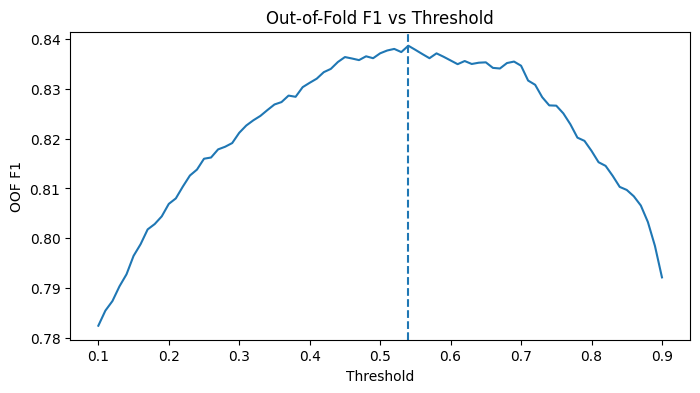

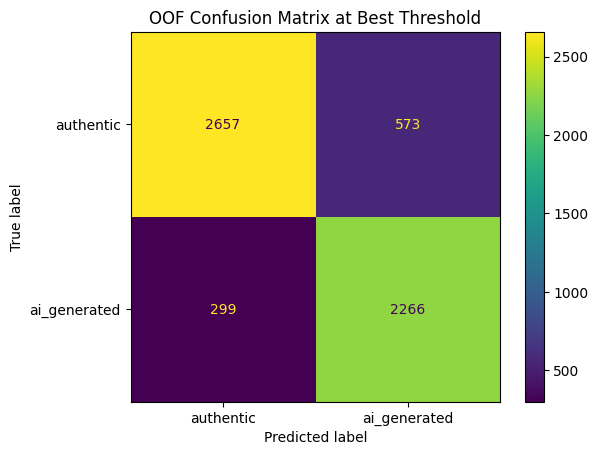

              precision    recall  f1-score   support

   authentic       0.90      0.82      0.86      3230
ai_generated       0.80      0.88      0.84      2565

    accuracy                           0.85      5795
   macro avg       0.85      0.85      0.85      5795
weighted avg       0.85      0.85      0.85      5795



,fold,phase,epoch,train_loss,train_f1,val_loss,val_f1
0,1,1,1,0.574613,0.682081,0.520786,0.750847
1,1,1,2,0.473794,0.770651,0.521534,0.755700
2,1,1,3,0.442870,0.786475,0.485437,0.771478
3,1,2,1,0.386646,0.808331,0.374162,0.825806
4,1,2,2,0.201109,0.910185,0.377116,0.829787


,image_id,label,target,oof_ai_generated_proba,oof_pred_target,oof_pred_label
0,ai5_3/Ai_generated_dataset/animals/image-10.png,ai_generated,1,0.592223,1,ai_generated
1,ai5_3/Ai_generated_dataset/animals/image-11.png,ai_generated,1,0.990277,1,ai_generated
2,ai5_3/Ai_generated_dataset/animals/image-12.png,ai_generated,1,0.991728,1,ai_generated
3,ai5_3/Ai_generated_dataset/animals/image-13.png,ai_generated,1,0.999885,1,ai_generated
4,ai5_3/Ai_generated_dataset/animals/image-14.png,ai_generated,1,0.999081,1,ai_generated


In [40]:
thresholds = np.linspace(0.1, 0.9, 81)
best_thresh = 0.5
best_thresh_f1 = -1.0
threshold_results = []

for t in thresholds:
    preds = (oof_probs >= t).astype(int)
    f1 = f1_score(oof_true, preds)
    threshold_results.append((t, f1))
    if f1 > best_thresh_f1:
        best_thresh_f1 = f1
        best_thresh = t

print("Best OOF threshold   :", best_thresh)
print("Best OOF threshold F1:", best_thresh_f1)

threshold_df = pd.DataFrame(threshold_results, columns=["threshold", "f1"])
display(threshold_df.sort_values("f1", ascending=False).head())

plt.figure(figsize=(8, 4))
plt.plot(threshold_df["threshold"], threshold_df["f1"])
plt.axvline(best_thresh, linestyle="--")
plt.xlabel("Threshold")
plt.ylabel("OOF F1")
plt.title("Out-of-Fold F1 vs Threshold")
plt.show()

oof_preds_best = (oof_probs >= best_thresh).astype(int)
cm = confusion_matrix(oof_true, oof_preds_best)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[CONFIG["negative_label"], CONFIG["positive_label"]],
)
disp.plot()
plt.title("OOF Confusion Matrix at Best Threshold")
plt.show()

print(classification_report(
    oof_true,
    oof_preds_best,
    target_names=[CONFIG["negative_label"], CONFIG["positive_label"]],
))

oof_df = train_df[["image_id", "label", "target"]].copy()
oof_df["oof_ai_generated_proba"] = oof_probs
oof_df["oof_pred_target"] = oof_preds_best
oof_df["oof_pred_label"] = oof_df["oof_pred_target"].map(id2label)

if CONFIG["save_oof_csv"]:
    oof_df.to_csv(REPORTS_DIR / "oof_predictions.csv", index=False)
    threshold_df.to_csv(REPORTS_DIR / "threshold_results.csv", index=False)

history_df = pd.DataFrame(all_histories)
history_df.to_csv(REPORTS_DIR / "training_history.csv", index=False)

with open(REPORTS_DIR / "run_config.json", "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2)

display(history_df.head())
display(oof_df.head())

## 8. Test prediction helpers

In [41]:
def predict_test(model, loader, device):
    model.eval()
    image_ids = []
    probs = []

    with torch.no_grad():
        for images, batch_ids in tqdm(loader, desc="Predicting test"):
            images = images.to(device, non_blocking=True)
            outputs = model(images)
            batch_probs = torch.softmax(outputs, dim=1)[:, 1]

            probs.extend(batch_probs.cpu().numpy())
            image_ids.extend(batch_ids)

    return pd.DataFrame({
        "image_id": image_ids,
        "ai_generated_proba": probs,
    })

def load_fold_model(model_path):
    model = build_model()
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    model.eval()
    return model

test_dataset = ManifestImageDataset(test_df, transform=val_transform, is_test=True)
test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available(),
)

## 9. Best-fold submission

In [42]:
best_fold_test_pred_df = predict_test(best_fold_model, test_loader, DEVICE)
best_fold_test_pred_df["pred_target"] = (best_fold_test_pred_df["ai_generated_proba"] >= best_thresh).astype(int)
best_fold_test_pred_df["ground_truth"] = best_fold_test_pred_df["pred_target"]

if CONFIG["save_test_probs_csv"]:
    best_fold_test_pred_df.to_csv(REPORTS_DIR / "best_fold_test_predictions.csv", index=False)

best_fold_submission_df = best_fold_test_pred_df[["image_id", "ground_truth"]].copy()

if CONFIG["save_submission_csv"]:
    best_fold_submission_df.to_csv(SUBMISSIONS_DIR / "submission_best_fold.csv", index=False)

display(best_fold_submission_df.head())

Predicting test: 100%|██████████| 65/65 [00:07<00:00,  8.14it/s]


,image_id,ground_truth
0,000317ef-6928-48ca-9b51-7742ab8dfb86.jpg,0
1,000a811d-cf8f-4b5b-be75-bd9f1a73c098.jpg,0
2,003a1394-83c5-41c0-9cd5-18ac89397c7b.jpg,0
3,00888016-16c4-4ce7-a03e-073f04a1a9c8.jpg,1
4,00e301e1-7520-4abb-8007-9e00a0b04da6.jpg,0


## 10. Fold-ensemble submission

In [43]:
fold_test_preds = []

for fold_id in range(1, CONFIG["n_splits"] + 1):
    model_path = MODELS_DIR / f"best_resnet50_fold{fold_id}.pt"
    print(f"Loading fold {fold_id} model from {model_path}")
    model = load_fold_model(model_path)

    fold_pred_df = predict_test(model, test_loader, DEVICE)
    fold_pred_df = fold_pred_df.rename(columns={
        "ai_generated_proba": f"fold_{fold_id}_proba"
    })
    fold_test_preds.append(fold_pred_df)

ensemble_df = fold_test_preds[0].copy()
for df in fold_test_preds[1:]:
    ensemble_df = ensemble_df.merge(df, on="image_id", how="inner")

proba_cols = [f"fold_{fold_id}_proba" for fold_id in range(1, CONFIG["n_splits"] + 1)]
ensemble_df["ai_generated_proba"] = ensemble_df[proba_cols].mean(axis=1)
ensemble_df["pred_target"] = (ensemble_df["ai_generated_proba"] >= best_thresh).astype(int)
ensemble_df["ground_truth"] = ensemble_df["pred_target"]

if CONFIG["save_test_probs_csv"]:
    ensemble_df.to_csv(REPORTS_DIR / "fold_ensemble_test_predictions.csv", index=False)

ensemble_submission_df = ensemble_df[["image_id", "ground_truth"]].copy()

if CONFIG["save_submission_csv"]:
    ensemble_submission_df.to_csv(SUBMISSIONS_DIR / "submission_fold_ensemble.csv", index=False)

print("Saved ensemble submission to:", SUBMISSIONS_DIR / "submission_fold_ensemble.csv")
display(ensemble_submission_df.head())

Loading fold 1 model from /home/tbeliere/Projects/DCU/AML_PJ/outputs/experiments/resnet50_etsy_ai5_3_v1/models/best_resnet50_fold1.pt


Predicting test: 100%|██████████| 65/65 [00:07<00:00,  8.34it/s]


Loading fold 2 model from /home/tbeliere/Projects/DCU/AML_PJ/outputs/experiments/resnet50_etsy_ai5_3_v1/models/best_resnet50_fold2.pt


Predicting test: 100%|██████████| 65/65 [00:07<00:00,  8.34it/s]


Loading fold 3 model from /home/tbeliere/Projects/DCU/AML_PJ/outputs/experiments/resnet50_etsy_ai5_3_v1/models/best_resnet50_fold3.pt


Predicting test: 100%|██████████| 65/65 [00:07<00:00,  8.17it/s]


... (2 outputs left out)

Loading fold 5 model from /home/tbeliere/Projects/DCU/AML_PJ/outputs/experiments/resnet50_etsy_ai5_3_v1/models/best_resnet50_fold5.pt


Predicting test: 100%|██████████| 65/65 [00:07<00:00,  8.79it/s]

Saved ensemble submission to: /home/tbeliere/Projects/DCU/AML_PJ/outputs/experiments/resnet50_etsy_ai5_3_v1/submissions/submission_fold_ensemble.csv


,image_id,ground_truth
0,000317ef-6928-48ca-9b51-7742ab8dfb86.jpg,0
1,000a811d-cf8f-4b5b-be75-bd9f1a73c098.jpg,0
2,003a1394-83c5-41c0-9cd5-18ac89397c7b.jpg,0
3,00888016-16c4-4ce7-a03e-073f04a1a9c8.jpg,1
4,00e301e1-7520-4abb-8007-9e00a0b04da6.jpg,0


# 11. Save Run metrics for comparison

In [44]:
# Metric extraction location - adjust path as needed
oof = pd.read_csv(REPORTS_DIR / "oof_predictions.csv")


# OOF metrics

y_true = oof["target"]
y_prob = oof["oof_ai_generated_proba"]

metrics = {}



# F1 @ 0.5
y_pred_05 = (y_prob >= 0.5).astype(int)
metrics["f1_05"] = float(f1_score(y_true, y_pred_05))

# best threshold
thresholds = np.arange(0.1, 0.91, 0.01)
best_f1 = 0
best_thr = 0.5

for t in thresholds:
    preds = (y_prob >= t).astype(int)
    f1 = f1_score(y_true, preds)
    if f1 > best_f1:
        best_f1 = f1
        best_thr = t

metrics["best_threshold"] = float(best_thr)
metrics["best_f1"] = float(best_f1)

# class metrics
y_pred_best = (y_prob >= best_thr).astype(int)

metrics["precision_ai_generated"] = float(
    precision_score(y_true, y_pred_best, pos_label=1)
)
metrics["recall_ai_generated"] = float(
    recall_score(y_true, y_pred_best, pos_label=1)
)

# save
metrics_path = REPORTS_DIR / "metrics_summary.json"
with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)

print("Saved metrics to:", metrics_path)
print(metrics)

Saved metrics to: /home/tbeliere/Projects/DCU/AML_PJ/outputs/experiments/resnet50_etsy_ai5_3_v1/reports/metrics_summary.json
{'f1_05': 0.8371156661786238, 'best_threshold': 0.5399999999999998, 'best_f1': 0.8386380458919319, 'precision_ai_generated': 0.7981683691440649, 'recall_ai_generated': 0.8834307992202729}


## 11. Notes

- Start with `train_manifest_etsy_only.csv` as the baseline.
- Then change `train_manifest_relpath` to `train_manifest_etsy_plus_external.csv` and rerun with the same hyperparameters.
- If the external dataset hurts F1, try turning on `use_class_weights` before more aggressive changes.
- Later, you can add a balanced external manifest and test that as a third experiment.